In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score



In [3]:
pd.set_option("display.float_format",lambda x: f"{x:,.2f}")

In [5]:
df=pd.read_csv("house_prices_dataset.csv")

In [6]:
df.shape

(10000, 5)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   square_feet           10000 non-null  float64
 1   num_rooms             10000 non-null  int64  
 2   age                   10000 non-null  int64  
 3   distance_to_city(km)  10000 non-null  float64
 4   price                 10000 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 390.8 KB


In [8]:
df.isnull().sum()

square_feet             0
num_rooms               0
age                     0
distance_to_city(km)    0
price                   0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
numeric_cols=df.select_dtypes(include="number").columns
df[numeric_cols]=df[numeric_cols].fillna(df[numeric_cols].median())

In [11]:
df.isnull().sum()

square_feet             0
num_rooms               0
age                     0
distance_to_city(km)    0
price                   0
dtype: int64

In [12]:
df.shape

(10000, 5)

,square_feet,num_rooms,age,distance_to_city(km),price
count,"10,000.00","10,000.00","10,000.00","10,000.00","10,000.00"
mean,"1,999.15",4.50,49.52,15.36,"263,011.57"
std,501.02,1.71,28.99,8.33,"98,336.95"
min,500.00,2.00,0.00,1.00,"-95,613.14"
25%,"1,663.70",3.00,24.00,8.12,"196,791.51"
50%,"1,998.70",4.00,49.00,15.40,"262,497.36"
75%,"2,335.54",6.00,75.00,22.45,"330,445.58"
max,"3,963.12",7.00,99.00,29.99,"660,168.26"


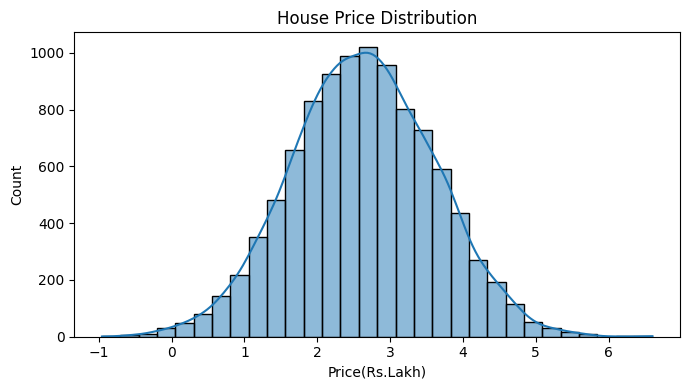

In [14]:
display(df.describe().round(2))
plt.figure(figsize=(7,4))
sns.histplot(df["price"]/100000,bins=30,kde=True)
plt.title("House Price Distribution")
plt.xlabel("Price(Rs.Lakh)")
plt.tight_layout()
plt.show()

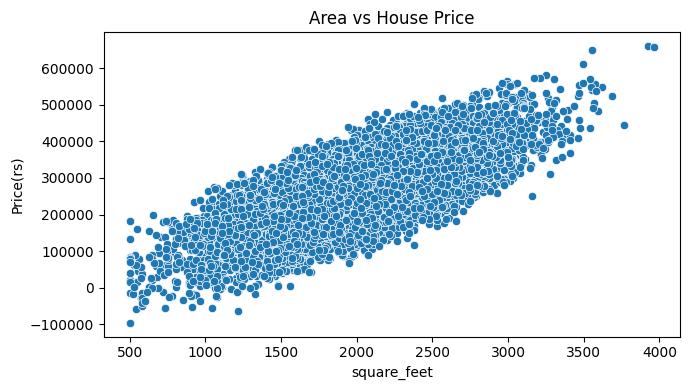

In [15]:
plt.figure(figsize=(7,4))
sns.scatterplot(data=df,x="square_feet", y="price")
plt.title("Area vs House Price")
plt.ylabel("Price(rs)")
plt.tight_layout()
plt.show()

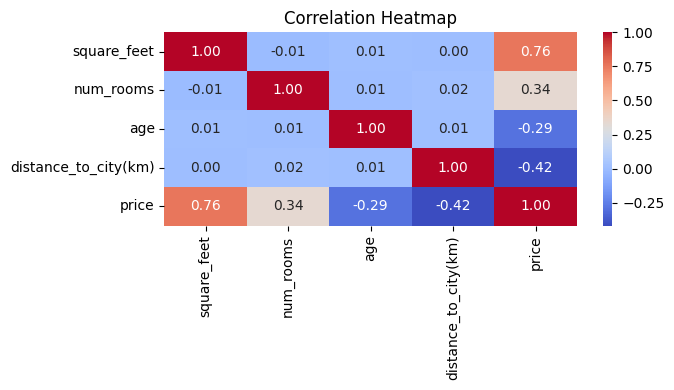

In [16]:
plt.figure(figsize=(7,4))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [17]:
x=df.drop(columns=["price"])
y=df["price"]

In [18]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [19]:
print("Training rows:",x_train.shape[0])
print("Testing rows:",x_test.shape[0])

Training rows: 8000
Testing rows: 2000


In [20]:
model=LinearRegression()
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [21]:
y

0      200,374.09
1      268,784.85
2      315,020.86
3      355,111.47
4      234,197.12
          ...    
9995   431,344.27
9996     6,650.27
9997   233,698.38
9998   280,766.83
9999   342,895.31
Name: price, Length: 10000, dtype: float64

In [22]:
y_pred=model.predict(x_test)

In [23]:
print(y_pred)

[316636.89860441 245793.09538071 222084.4079465  ... 261253.08848688
 254935.74566457 204914.72083005]


In [24]:
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mean_squared_error(y_test,y_pred))
r2=r2_score(y_test,y_pred)

print(f"MAE:{mae:,.0f}")
print(f"RMSE:{rmse:,.0f}")
print(f"R2 Score:{r2:.3f}")

MAE:15,596
RMSE:19,658
R2 Score:0.960


In [25]:
result=pd.DataFrame({"Actual_Price":y_test,"Predicted_Price":y_pred})
display(result.head(10).round(0))

,Actual_Price,Predicted_Price
6252,"350,281.00","316,637.00"
4684,"238,534.00","245,793.00"
1731,"223,551.00","222,084.00"
4742,"233,197.00","231,463.00"
4521,"387,860.00","378,539.00"
6340,"80,706.00","126,495.00"
576,"210,893.00","247,179.00"
5202,"157,577.00","203,474.00"
6363,"260,014.00","248,668.00"
439,"203,015.00","204,065.00"


In [26]:
new_house=pd.DataFrame([{
    "square_feet":1500,
    "num_rooms":4,
    "age":8,
    "distance_to_city(km)":5.0
    
}])

predicted_price=model.predict(new_house)[0]
print(f"Estimated house price: Rs {predicted_price:,.0f}")

Estimated house price: Rs 271,759
